# WHEN NATURE STRIKES
## 02 – Natural Disaster Impact Analysis

### 1. Introduction

This analysis investigates the human and economic
consequences of different types of natural disasters.

While frequency analysis identifies how often disasters
occur, impact analysis helps determine how destructive
these events are.

The analysis focuses on three major impact measures:

1. Total Deaths – Human fatalities.
2. Total Affected – Population affected by disasters.
3. Adjusted Economic Damage – Financial losses adjusted
   for inflation and expressed in million US dollars.

### 2. Research Questions

1. Which disaster types cause the highest total deaths?
2. Which disaster types affect the largest populations?
3. Which disaster types cause the greatest economic damage?
4. Which disaster types have the highest average impact
   per reported event?
5. Are the most frequent disasters also the most destructive?

### 3. Dataset

- Primary dataset: natural_disaster_events.csv
- Supporting dataset: natural_disaster_type_summary.csv
- Total unique events: 15,727
- Time coverage: 1900–2026
- Source: EM-DAT, CRED / UCLouvain

### 4. Methodology

- Group events by Disaster Type.
- Calculate total reported deaths.
- Calculate total reported affected population.
- Calculate total adjusted economic damage.
- Calculate average impact per event with a reported value.
- Examine reporting coverage for each measure.
- Compare disaster frequency with destructiveness.

### 5. Important Data Considerations

Missing impact values are not treated as zero.

An event is considered reported for a particular measure
only when its event-level value is available.

Economic damage is measured using the inflation-adjusted
million US dollar column.

Totals and averages are interpreted separately because
frequent disaster types may have higher aggregate impacts
simply due to their greater number of events.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 7)

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
# Identify the repository root

ROOT = Path.cwd()

if not (ROOT / "data" / "processed").exists():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "processed"

# Load datasets

events = pd.read_csv(
    DATA_DIR / "natural_disaster_events.csv",
    encoding="utf-8-sig"
)

type_summary = pd.read_csv(
    DATA_DIR / "natural_disaster_type_summary.csv",
    encoding="utf-8-sig"
)

print("Datasets loaded successfully!")
print("Repository root:", ROOT)

Datasets loaded successfully!
Repository root: c:\Users\Shasa\Desktop\MINE\when-nature-strikes


In [ ]:
#Examine impact reporting coverage

In [7]:
impact_columns = [
    "Total Deaths",
    "Total Affected",
    "Total Damage, Adjusted (million US$)"
]

coverage_data = []

for column in impact_columns:

    reported = events[column].notna().sum()
    missing = events[column].isna().sum()

    coverage_data.append({
        "Impact Measure": column,
        "Reported Events": reported,
        "Missing Events": missing,
        "Coverage Percentage": round(
            reported / len(events) * 100, 2
        )
    })

coverage_df = pd.DataFrame(coverage_data)

display(coverage_df)

,Impact Measure,Reported Events,Missing Events,Coverage Percentage
0,Total Deaths,11655,4072,74.11
1,Total Affected,12366,3361,78.63
2,"Total Damage, Adjusted (million US$)",5251,10476,33.39


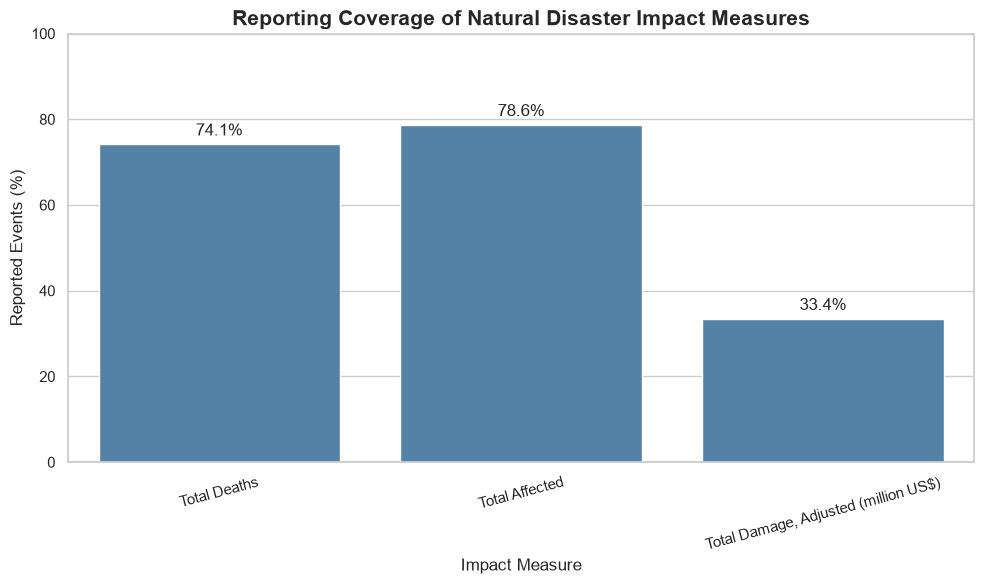

In [8]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=coverage_df,
    x="Impact Measure",
    y="Coverage Percentage",
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=4)

plt.title(
    "Reporting Coverage of Natural Disaster Impact Measures",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Impact Measure")
plt.ylabel("Reported Events (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)

plt.tight_layout()

impact_dir = ROOT / "visualizations" / "impacts"
impact_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    impact_dir / "01_impact_reporting_coverage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
#Calculate impact by disaster type

In [9]:
impact_measures = {
    "Total Deaths": "Total Deaths Reported Country Impacts",
    "Total Affected": "Total Affected Reported Country Impacts",
    "Total Damage, Adjusted (million US$)": (
        "Total Damage, Adjusted (million US$) Reported Country Impacts"
    )
}

impact_rows = []

for disaster_type, group in events.groupby("Disaster Type"):

    row = {
        "Disaster Type": disaster_type,
        "Unique Events": group["Event ID"].nunique()
    }

    for measure, reported_column in impact_measures.items():

        values = group[measure]

        # Sum only available values; preserve missing if all are missing
        row[f"{measure} - Total"] = values.sum(min_count=1)

        # Average only among events with reported values
        row[f"{measure} - Average"] = values.mean()

        # Number of events with reported values
        row[f"{measure} - Reported Events"] = values.notna().sum()

        # Number of country-impact records reporting this measure
        row[f"{measure} - Reported Country Impacts"] = (
            group[reported_column].sum()
        )

    impact_rows.append(row)

impact_summary = pd.DataFrame(impact_rows)

display(impact_summary)

,Disaster Type,Unique Events,Total Deaths - Total,Total Deaths - Average,Total Deaths - Reported Events,Total Deaths - Reported Country Impacts,Total Affected - Total,Total Affected - Average,Total Affected - Reported Events,Total Affected - Reported Country Impacts,"Total Damage, Adjusted (million US$) - Total","Total Damage, Adjusted (million US$) - Average","Total Damage, Adjusted (million US$) - Reported Events","Total Damage, Adjusted (million US$) - Reported Country Impacts"
0,Animal incident,1,12.0,12.000000,1,1,5.000000e+00,5.000000e+00,1,1,NaN,NaN,0,0
1,Drought,647,11734353.0,175139.597015,67,73,3.028731e+09,6.349540e+06,477,553,456883.972,2228.702302,205,234
2,Earthquake,1573,2440922.0,2051.194958,1190,1244,2.548584e+08,1.923459e+05,1325,1385,1803517.195,2881.017883,626,645
3,Epidemic,1447,9629942.0,7747.338697,1243,1303,5.086409e+07,4.046467e+04,1257,1331,0.061,0.061000,1,1
4,Extreme temperature,433,397964.0,1093.307692,364,648,1.414168e+08,7.813080e+05,181,203,143465.781,2391.096350,60,72
5,Flood,5814,7030614.0,1618.838130,4343,4565,4.111435e+09,8.056899e+05,5103,5358,1906588.840,989.407805,1927,1986
6,Fog,1,4000.0,4000.000000,1,1,NaN,NaN,0,0,NaN,NaN,0,0
7,Glacial lake outburst flood,7,478.0,79.666667,6,7,9.414400e+04,2.353600e+04,4,4,749.504,374.752000,2,2
8,Impact,1,NaN,NaN,0,0,3.014910e+05,3.014910e+05,1,1,45.605,45.605000,1,1
9,Infestation,78,NaN,NaN,0,0,3.202200e+06,6.404400e+05,5,5,454.451,113.612750,4,4


In [10]:
death_ranking = impact_summary.sort_values(
    "Total Deaths - Total",
    ascending=False,
    na_position="last"
)

affected_ranking = impact_summary.sort_values(
    "Total Affected - Total",
    ascending=False,
    na_position="last"
)

damage_ranking = impact_summary.sort_values(
    "Total Damage, Adjusted (million US$) - Total",
    ascending=False,
    na_position="last"
)

print("TOP DISASTER TYPES BY TOTAL DEATHS")
display(
    death_ranking[
        ["Disaster Type", "Total Deaths - Total",
         "Total Deaths - Reported Events"]
    ].head(10)
)

print("TOP DISASTER TYPES BY TOTAL AFFECTED")
display(
    affected_ranking[
        ["Disaster Type", "Total Affected - Total",
         "Total Affected - Reported Events"]
    ].head(10)
)

print("TOP DISASTER TYPES BY ECONOMIC DAMAGE")
display(
    damage_ranking[
        ["Disaster Type",
         "Total Damage, Adjusted (million US$) - Total",
         "Total Damage, Adjusted (million US$) - Reported Events"]
    ].head(10)
)

TOP DISASTER TYPES BY TOTAL DEATHS


,Disaster Type,Total Deaths - Total,Total Deaths - Reported Events
1,Drought,11734353.0,67
3,Epidemic,9629942.0,1243
5,Flood,7030614.0,4343
2,Earthquake,2440922.0,1190
12,Storm,1435952.0,3219
4,Extreme temperature,397964.0,364
13,Volcanic activity,86945.0,96
11,Mass movement (wet),71714.0,830
14,Wildfire,5256.0,250
10,Mass movement (dry),4563.0,45


TOP DISASTER TYPES BY TOTAL AFFECTED


,Disaster Type,Total Affected - Total,Total Affected - Reported Events
5,Flood,4.111435e+09,5103
1,Drought,3.028731e+09,477
12,Storm,1.425982e+09,2891
2,Earthquake,2.548584e+08,1325
4,Extreme temperature,1.414168e+08,181
3,Epidemic,5.086409e+07,1257
14,Wildfire,1.903690e+07,362
11,Mass movement (wet),1.829669e+07,507
13,Volcanic activity,1.076402e+07,232
9,Infestation,3.202200e+06,5


TOP DISASTER TYPES BY ECONOMIC DAMAGE


,Disaster Type,"Total Damage, Adjusted (million US$) - Total","Total Damage, Adjusted (million US$) - Reported Events"
12,Storm,3494871.819,2096
5,Flood,1906588.840,1927
2,Earthquake,1803517.195,626
1,Drought,456883.972,205
14,Wildfire,272305.311,189
4,Extreme temperature,143465.781,60
11,Mass movement (wet),23776.071,91
13,Volcanic activity,15732.127,46
10,Mass movement (dry),2142.437,3
7,Glacial lake outburst flood,749.504,2


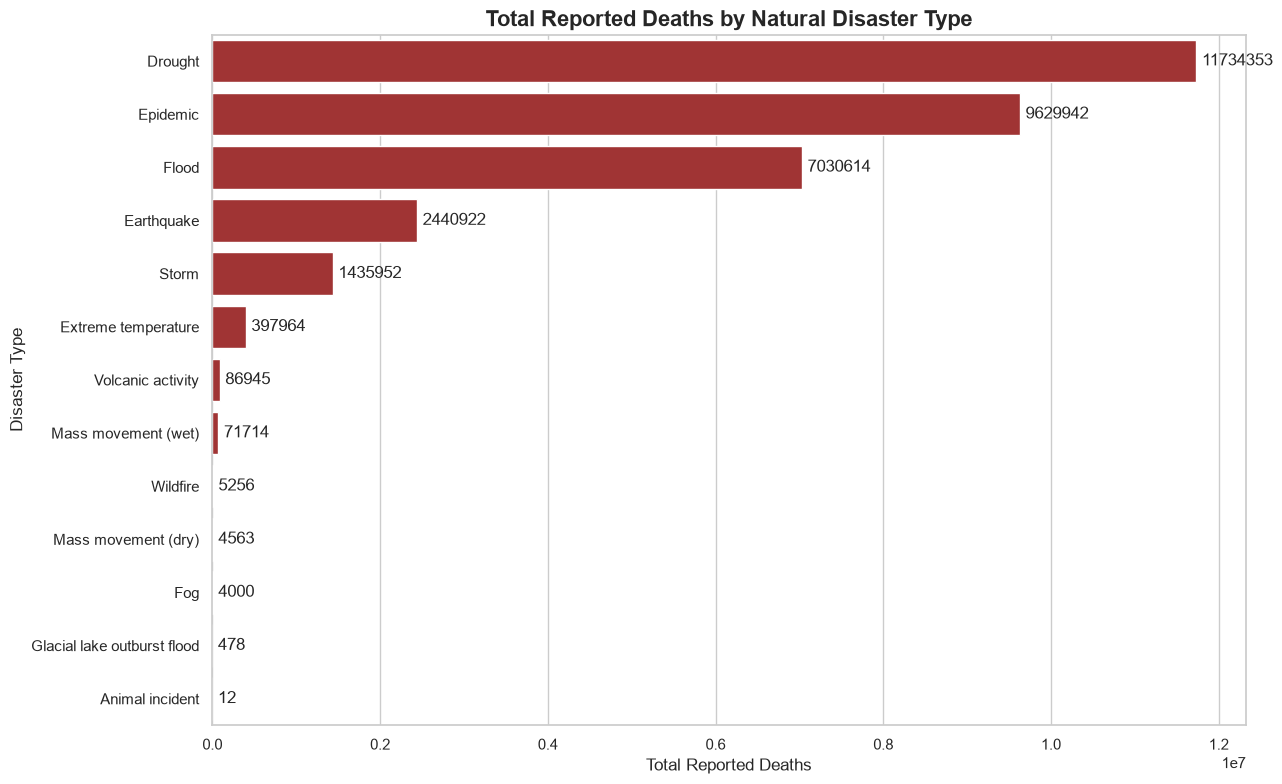

In [11]:
death_plot = death_ranking.dropna(
    subset=["Total Deaths - Total"]
)

plt.figure(figsize=(13, 8))

ax = sns.barplot(
    data=death_plot,
    x="Total Deaths - Total",
    y="Disaster Type",
    color="firebrick"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4)

plt.title(
    "Total Reported Deaths by Natural Disaster Type",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Total Reported Deaths")
plt.ylabel("Disaster Type")

plt.tight_layout()

plt.savefig(
    impact_dir / "02_deaths_by_disaster_type.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

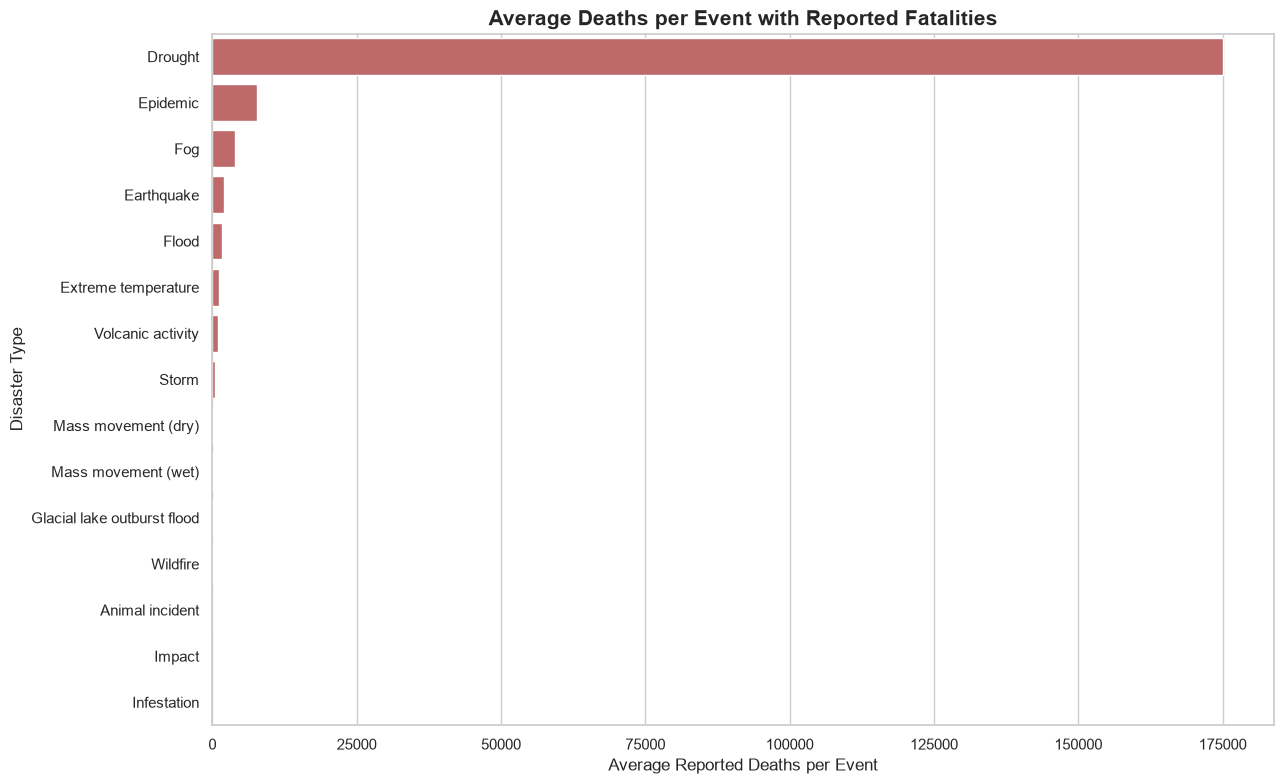

In [12]:
average_deaths = impact_summary.sort_values(
    "Total Deaths - Average",
    ascending=False,
    na_position="last"
)

plt.figure(figsize=(13, 8))

sns.barplot(
    data=average_deaths,
    x="Total Deaths - Average",
    y="Disaster Type",
    color="indianred"
)

plt.title(
    "Average Deaths per Event with Reported Fatalities",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Average Reported Deaths per Event")
plt.ylabel("Disaster Type")

plt.tight_layout()

plt.savefig(
    impact_dir / "03_average_deaths_per_event.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
#Human impact analysis: Population affected

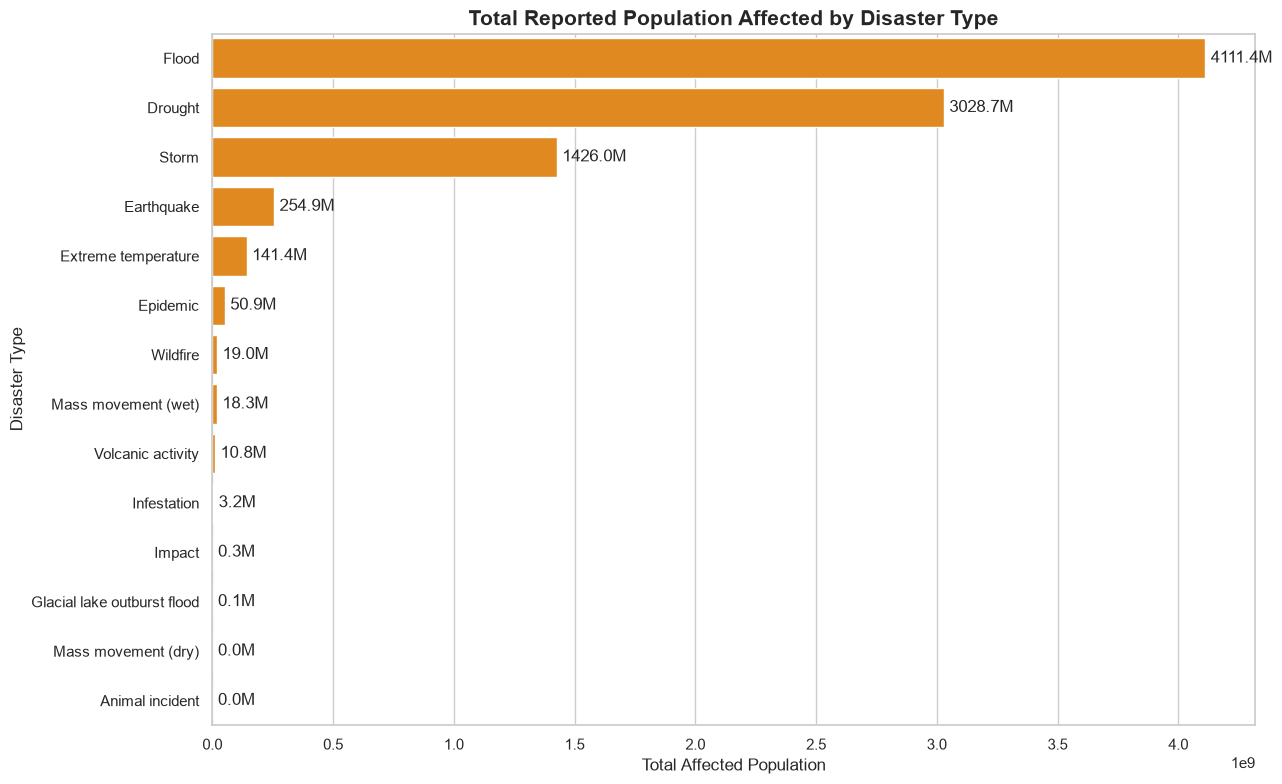

In [14]:
affected_plot = affected_ranking.dropna(
    subset=["Total Affected - Total"]
)

plt.figure(figsize=(13, 8))

ax = sns.barplot(
    data=affected_plot,
    x="Total Affected - Total",
    y="Disaster Type",
    color="darkorange"
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[
            f"{value / 1_000_000:.1f}M"
            for value in affected_plot["Total Affected - Total"]
        ],
        padding=4
    )

plt.title(
    "Total Reported Population Affected by Disaster Type",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Total Affected Population")
plt.ylabel("Disaster Type")

plt.tight_layout()

plt.savefig(
    impact_dir / "04_total_affected_population.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

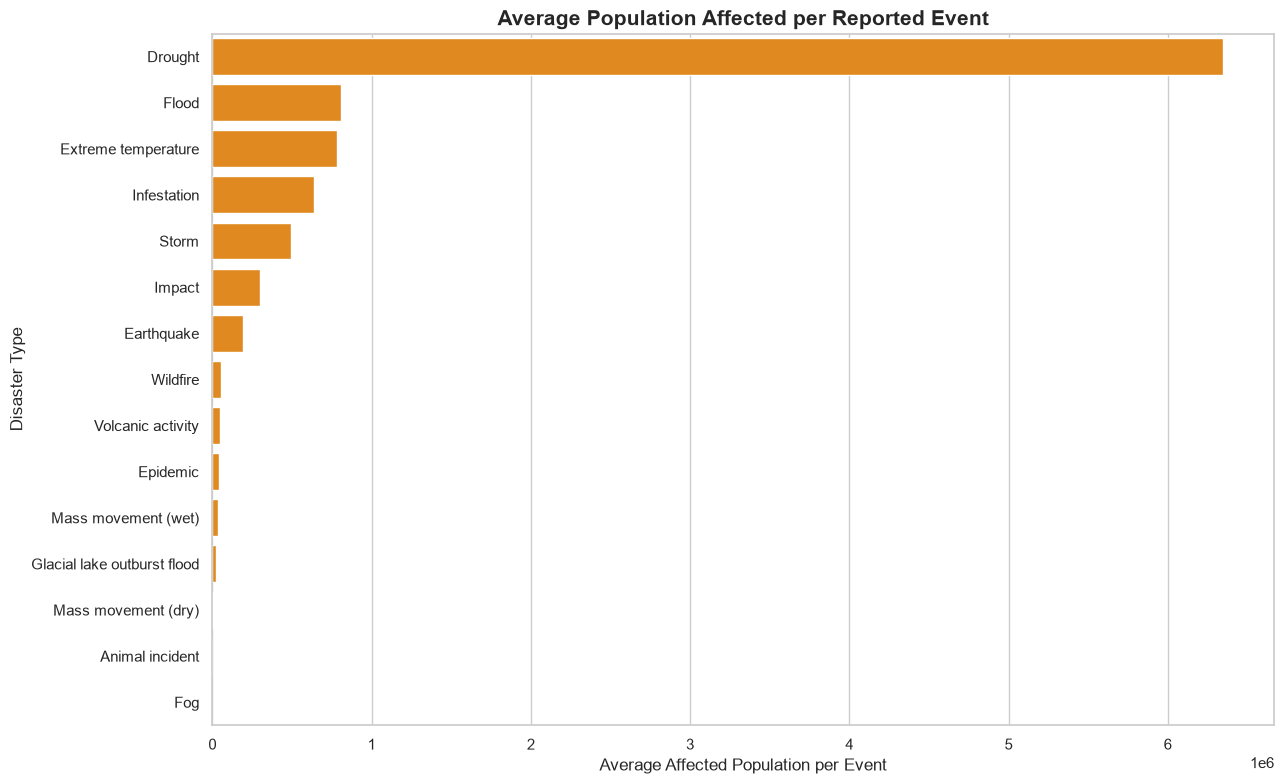

In [15]:
average_affected = impact_summary.sort_values(
    "Total Affected - Average",
    ascending=False,
    na_position="last"
)

plt.figure(figsize=(13, 8))

sns.barplot(
    data=average_affected,
    x="Total Affected - Average",
    y="Disaster Type",
    color="darkorange"
)

plt.title(
    "Average Population Affected per Reported Event",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Average Affected Population per Event")
plt.ylabel("Disaster Type")

plt.tight_layout()

plt.savefig(
    impact_dir / "05_average_affected_per_event.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
#Economic impact analysis

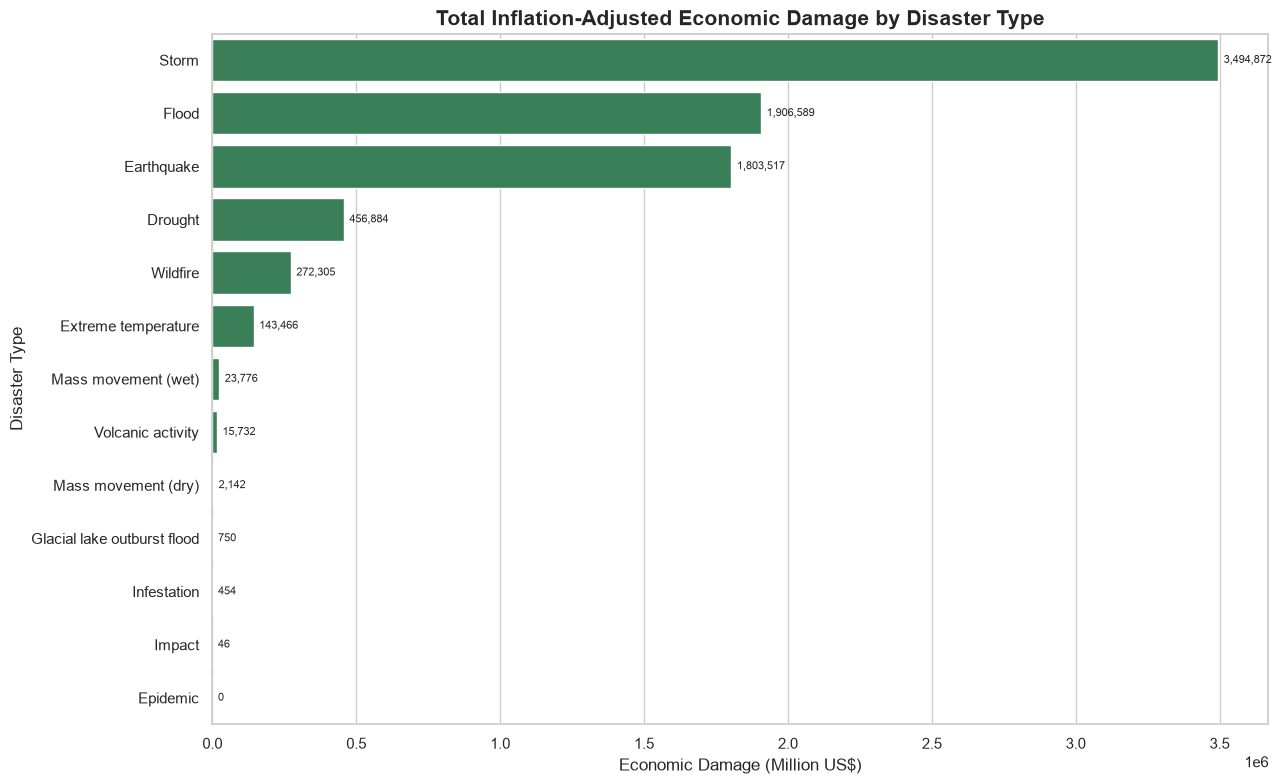

In [17]:
damage_plot = damage_ranking.dropna(
    subset=[
        "Total Damage, Adjusted (million US$) - Total"
    ]
)

plt.figure(figsize=(13, 8))

ax = sns.barplot(
    data=damage_plot,
    x="Total Damage, Adjusted (million US$) - Total",
    y="Disaster Type",
    color="seagreen"
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[
            f"{value:,.0f}"
            for value in damage_plot[
                "Total Damage, Adjusted (million US$) - Total"
            ]
        ],
        padding=4,
        fontsize=8
    )

plt.title(
    "Total Inflation-Adjusted Economic Damage by Disaster Type",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Economic Damage (Million US$)")
plt.ylabel("Disaster Type")

plt.tight_layout()

plt.savefig(
    impact_dir / "06_total_economic_damage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

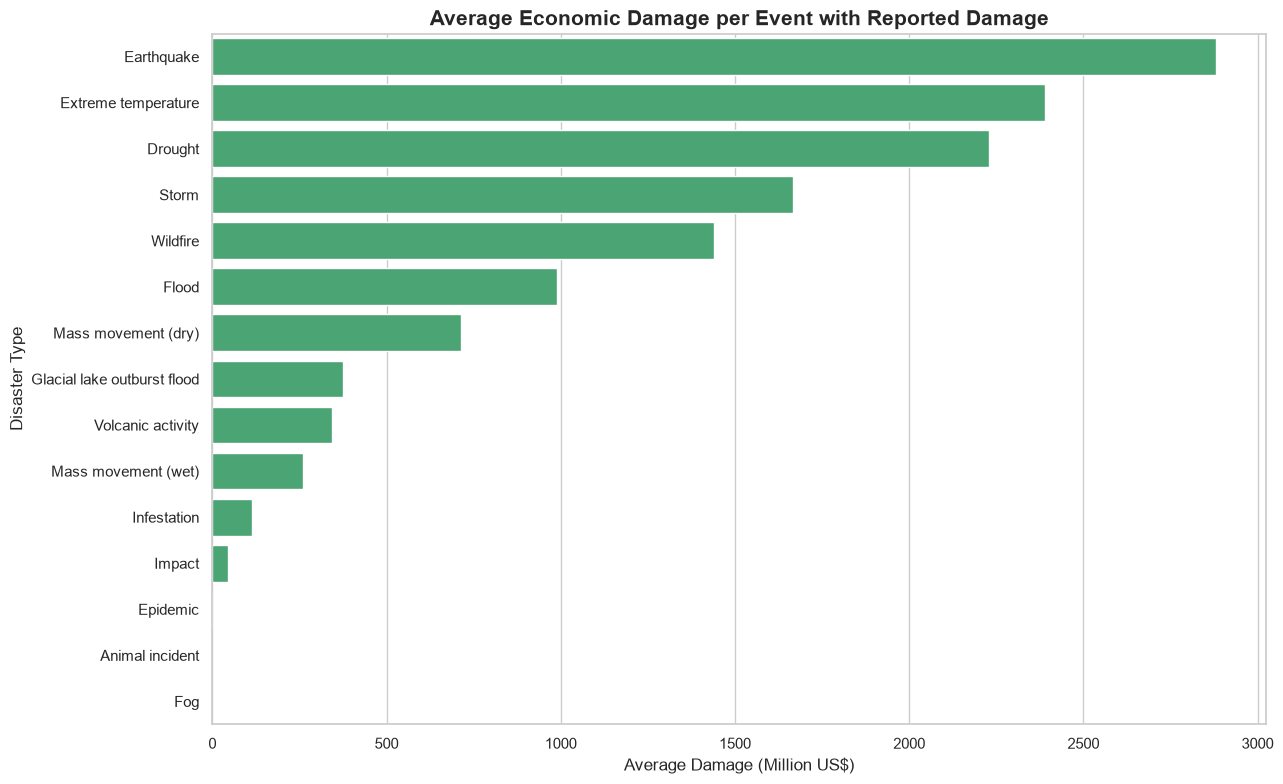

In [18]:
average_damage = impact_summary.sort_values(
    "Total Damage, Adjusted (million US$) - Average",
    ascending=False,
    na_position="last"
)

plt.figure(figsize=(13, 8))

sns.barplot(
    data=average_damage,
    x="Total Damage, Adjusted (million US$) - Average",
    y="Disaster Type",
    color="mediumseagreen"
)

plt.title(
    "Average Economic Damage per Event with Reported Damage",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Average Damage (Million US$)")
plt.ylabel("Disaster Type")

plt.tight_layout()

plt.savefig(
    impact_dir / "07_average_economic_damage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
#Frequency versus destructiveness

In [20]:
frequency_impact = impact_summary.copy()

display(
    frequency_impact[
        [
            "Disaster Type",
            "Unique Events",
            "Total Deaths - Average",
            "Total Affected - Average",
            "Total Damage, Adjusted (million US$) - Average"
        ]
    ].sort_values("Unique Events", ascending=False)
    
)

,Disaster Type,Unique Events,Total Deaths - Average,Total Affected - Average,"Total Damage, Adjusted (million US$) - Average"
5,Flood,5814,1618.838130,8.056899e+05,989.407805
12,Storm,4026,446.086362,4.932487e+05,1667.400677
2,Earthquake,1573,2051.194958,1.923459e+05,2881.017883
3,Epidemic,1447,7747.338697,4.046467e+04,0.061000
11,Mass movement (wet),867,86.402410,3.608815e+04,261.275505
1,Drought,647,175139.597015,6.349540e+06,2228.702302
14,Wildfire,508,21.024000,5.258814e+04,1440.768841
4,Extreme temperature,433,1093.307692,7.813080e+05,2391.096350
13,Volcanic activity,277,905.677083,4.639666e+04,342.002761
9,Infestation,78,NaN,6.404400e+05,113.612750


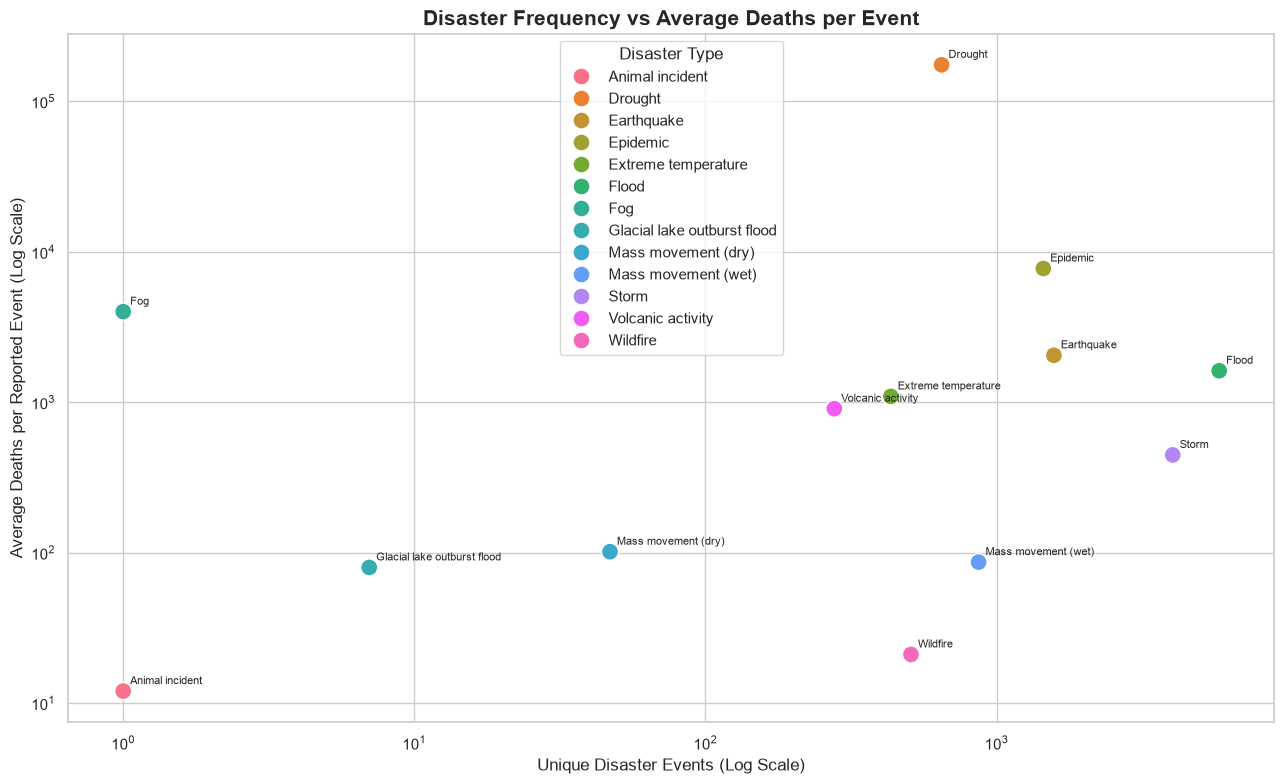

In [21]:
plot_data = frequency_impact.dropna(
    subset=["Total Deaths - Average"]
)

plot_data = plot_data[
    (plot_data["Unique Events"] > 0) &
    (plot_data["Total Deaths - Average"] > 0)
]

plt.figure(figsize=(13, 8))

sns.scatterplot(
    data=plot_data,
    x="Unique Events",
    y="Total Deaths - Average",
    hue="Disaster Type",
    s=150
)

for _, row in plot_data.iterrows():
    plt.annotate(
        row["Disaster Type"],
        (row["Unique Events"], row["Total Deaths - Average"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xscale("log")
plt.yscale("log")

plt.title(
    "Disaster Frequency vs Average Deaths per Event",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Unique Disaster Events (Log Scale)")
plt.ylabel("Average Deaths per Reported Event (Log Scale)")

plt.tight_layout()

plt.savefig(
    impact_dir / "08_frequency_vs_average_deaths.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

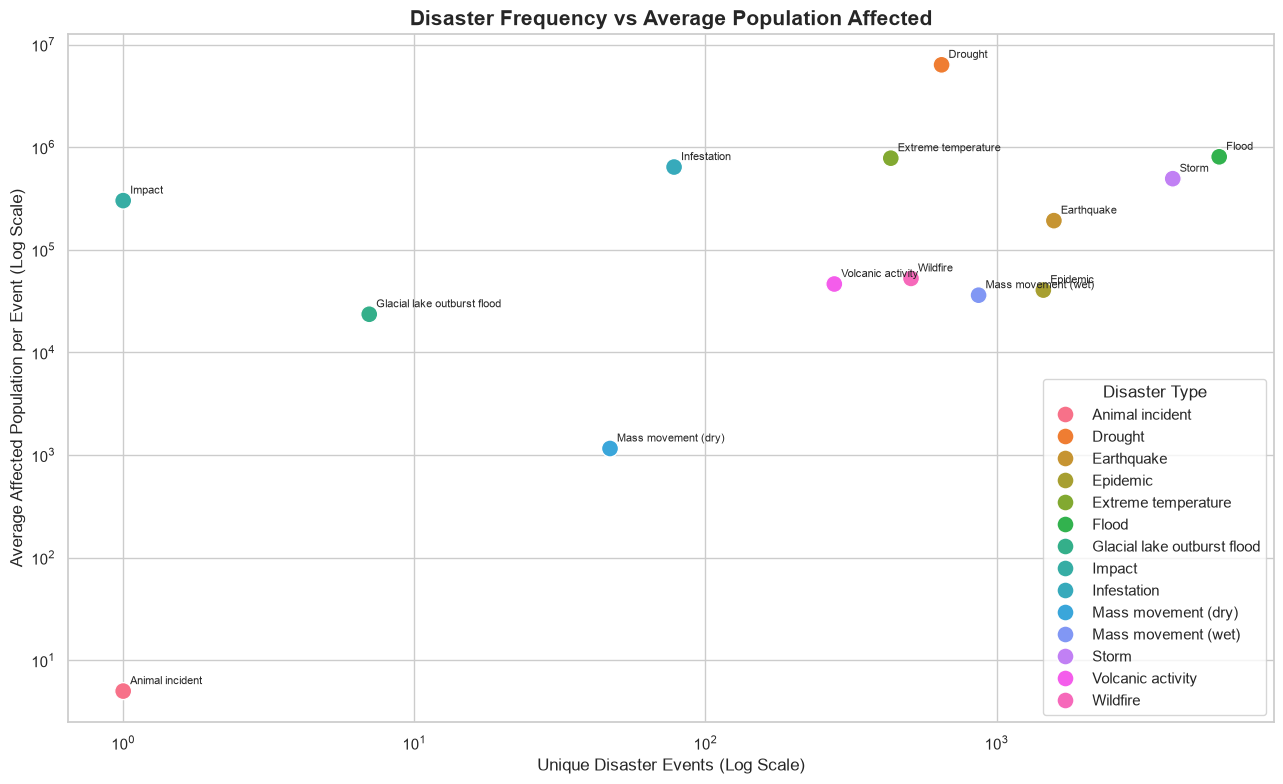

In [22]:
plot_data = frequency_impact.dropna(
    subset=["Total Affected - Average"]
)

plot_data = plot_data[
    (plot_data["Unique Events"] > 0) &
    (plot_data["Total Affected - Average"] > 0)
]

plt.figure(figsize=(13, 8))

sns.scatterplot(
    data=plot_data,
    x="Unique Events",
    y="Total Affected - Average",
    hue="Disaster Type",
    s=150
)

for _, row in plot_data.iterrows():
    plt.annotate(
        row["Disaster Type"],
        (row["Unique Events"], row["Total Affected - Average"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xscale("log")
plt.yscale("log")

plt.title(
    "Disaster Frequency vs Average Population Affected",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Unique Disaster Events (Log Scale)")
plt.ylabel("Average Affected Population per Event (Log Scale)")

plt.tight_layout()

plt.savefig(
    impact_dir / "09_frequency_vs_average_affected.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

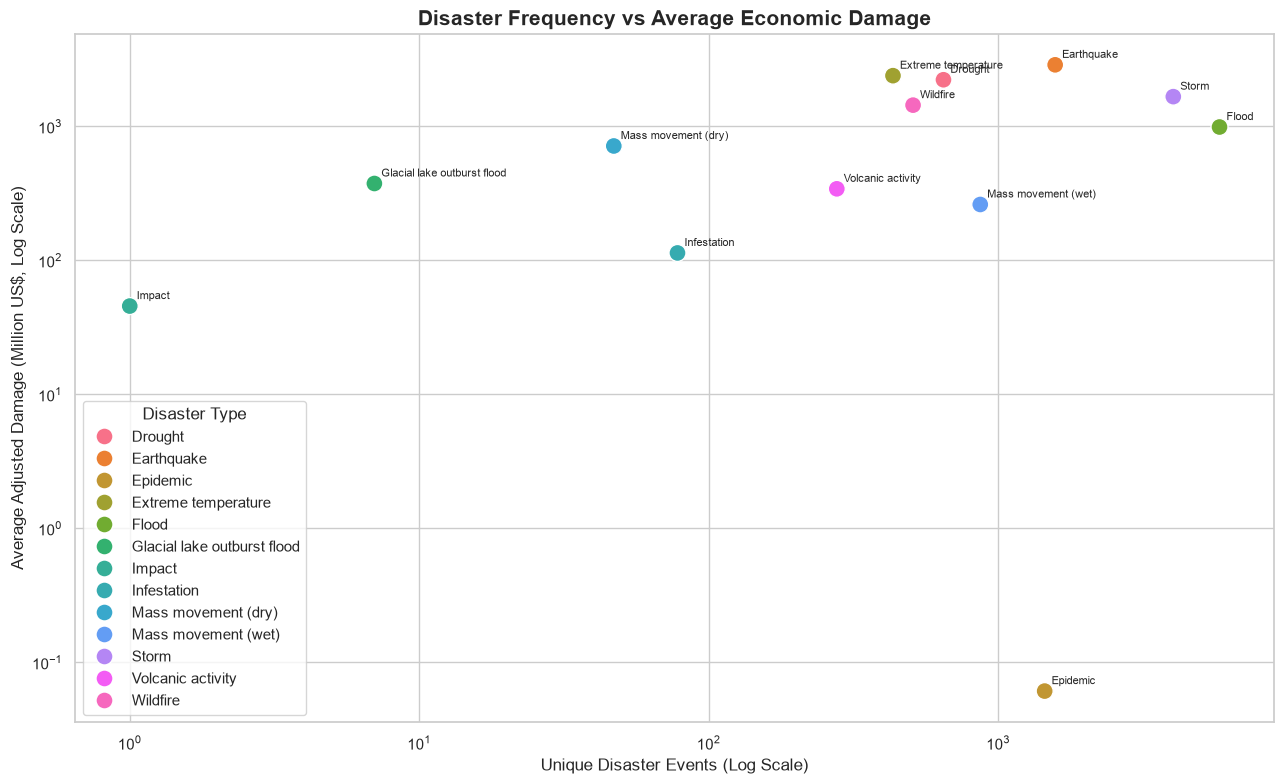

In [23]:
damage_average_column = (
    "Total Damage, Adjusted (million US$) - Average"
)

plot_data = frequency_impact.dropna(
    subset=[damage_average_column]
)

plot_data = plot_data[
    (plot_data["Unique Events"] > 0) &
    (plot_data[damage_average_column] > 0)
]

plt.figure(figsize=(13, 8))

sns.scatterplot(
    data=plot_data,
    x="Unique Events",
    y=damage_average_column,
    hue="Disaster Type",
    s=150
)

for _, row in plot_data.iterrows():
    plt.annotate(
        row["Disaster Type"],
        (row["Unique Events"], row[damage_average_column]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xscale("log")
plt.yscale("log")

plt.title(
    "Disaster Frequency vs Average Economic Damage",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Unique Disaster Events (Log Scale)")
plt.ylabel("Average Adjusted Damage (Million US$, Log Scale)")

plt.tight_layout()

plt.savefig(
    impact_dir / "10_frequency_vs_average_damage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
#top impact rankings

In [25]:
ranking_columns = [
    "Disaster Type",
    "Unique Events",
    "Total Deaths - Total",
    "Total Deaths - Average",
    "Total Affected - Total",
    "Total Affected - Average",
    "Total Damage, Adjusted (million US$) - Total",
    "Total Damage, Adjusted (million US$) - Average"
]

display(
    impact_summary[ranking_columns].sort_values(
        "Unique Events",
        ascending=False
    )
)

,Disaster Type,Unique Events,Total Deaths - Total,Total Deaths - Average,Total Affected - Total,Total Affected - Average,"Total Damage, Adjusted (million US$) - Total","Total Damage, Adjusted (million US$) - Average"
5,Flood,5814,7030614.0,1618.838130,4.111435e+09,8.056899e+05,1906588.840,989.407805
12,Storm,4026,1435952.0,446.086362,1.425982e+09,4.932487e+05,3494871.819,1667.400677
2,Earthquake,1573,2440922.0,2051.194958,2.548584e+08,1.923459e+05,1803517.195,2881.017883
3,Epidemic,1447,9629942.0,7747.338697,5.086409e+07,4.046467e+04,0.061,0.061000
11,Mass movement (wet),867,71714.0,86.402410,1.829669e+07,3.608815e+04,23776.071,261.275505
1,Drought,647,11734353.0,175139.597015,3.028731e+09,6.349540e+06,456883.972,2228.702302
14,Wildfire,508,5256.0,21.024000,1.903690e+07,5.258814e+04,272305.311,1440.768841
4,Extreme temperature,433,397964.0,1093.307692,1.414168e+08,7.813080e+05,143465.781,2391.096350
13,Volcanic activity,277,86945.0,905.677083,1.076402e+07,4.639666e+04,15732.127,342.002761
9,Infestation,78,NaN,NaN,3.202200e+06,6.404400e+05,454.451,113.612750


In [26]:
output_dir = ROOT / "analysis" / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

impact_summary.to_csv(
    output_dir / "disaster_impact_summary.csv",
    index=False
)

coverage_df.to_csv(
    output_dir / "impact_reporting_coverage.csv",
    index=False
)

print("Impact analysis tables exported successfully!")

Impact analysis tables exported successfully!
